# Evaluate baseline vs. RAG vs. agent

Scores the three systems against the answer key for the 54 Starhawk requirements:

| System | Notebook | Output read here |
|---|---|---|
| Keyword baseline | `04_keyword_baseline.ipynb` | `data/baseline_predictions.csv` |
| RAG | `08_generate_report.ipynb` | `data/report.json` |
| Tool-calling agent | `11_tool_calling_agent.ipynb` | `data/report_agent.json` |

Nothing is re-run and no API key is needed: this notebook only reads the saved outputs.

**What is scored**
- **Status:** does the system's ACCEPTABLE / NEEDS_REVIEW match the answer key?
- **Precision / recall on NEEDS_REVIEW:** of the requirements a system flags, how many should be flagged (precision);
  of the requirements that should be flagged, how many it caught (recall).
- **Issue code:** for requirements the key flags, does the system name the key's issue code?
- **Citations:** does every NASA clause a system cites exist in `addressable_clauses.csv`?

**Which rows to trust most.** The answer key has three splits. `CALIBRATION` (7) was visible while the systems were
built, and the baseline's keyword rules were written alongside the team's manual review that fills `NOT_IN_BENCHMARK` (31).
`HOLDOUT` (16) was not used to tune anything, so it is the fairest comparison.

In [1]:
import json
from pathlib import Path

import pandas as pd

pd.set_option("display.max_colwidth", 120)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "answer_key.csv").exists())
DATA = ROOT / "data"

key = pd.read_csv(DATA / "answer_key.csv")
req_key = key[key["scope"] == "REQUIREMENT"].rename(columns={"target_ids": "req_id"})   # the 54 single-requirement rows
clauses = pd.read_csv(DATA / "addressable_clauses.csv")
srs = pd.read_csv(DATA / "srs_requirements.csv")

print(len(req_key), "requirement rows in the answer key")
print(req_key.groupby(["split", "expected_outcome"]).size().unstack(fill_value=0))

54 requirement rows in the answer key
expected_outcome  ACCEPTABLE  NEEDS_REVIEW
split                                     
CALIBRATION                1             6
HOLDOUT                    8             8
NOT_IN_BENCHMARK          23             8


## Put all three systems in the same shape

One row per requirement: `status`, a list of issue `codes`, and a list of `citations`.

The baseline cites clause IDs (`chunk_id`). The RAG and agent reports cite a document and section, e.g.
`("NASA-HDBK-2203-5.09", "§7.1")`, so citations are checked against each format separately.

In [2]:
# Same mapping as report_schema.py, copied so this notebook only needs pandas
SOURCE_TO_DOCUMENT = {"NPR 7150.2D": "NPR-7150.2D", "SWEHB 5.09": "NASA-HDBK-2203-5.09"}

real_clause_ids = set(clauses["chunk_id"])
real_doc_sections = {(SOURCE_TO_DOCUMENT[s], f"§{sec}") for s, sec in zip(clauses["source"], clauses["section"])}


def load_baseline(path):
    df = pd.read_csv(path)
    return pd.DataFrame({
        "req_id": df["req_id"],
        "status": df["quality_status"],
        "codes": df["issue_codes"].fillna("NONE").str.split(";"),
        "citations": df["cited_chunk_ids"].fillna("").str.split(";").map(lambda ids: [i for i in ids if i]),
        "citation_ok": df["cited_chunk_ids"].fillna("").str.split(";").map(
            lambda ids: [i in real_clause_ids for i in ids if i]),
    })


def load_report(path):
    rows = []
    for r in json.loads(Path(path).read_text(encoding="utf-8"))["requirement_reviews"]:
        cites = [(n["document"], n["section"]) for issue in r["quality_issues"] for n in issue["nasa_references"]]
        rows.append({
            "req_id": r["requirement_id"],
            "status": r["quality_status"],
            "codes": [issue["issue_code"] for issue in r["quality_issues"]] or ["NONE"],
            "citations": cites,
            "citation_ok": [c in real_doc_sections for c in cites],
        })
    return pd.DataFrame(rows)


systems = {
    "baseline": load_baseline(DATA / "baseline_predictions.csv"),
    "rag": load_report(DATA / "report.json"),
    "agent": load_report(DATA / "report_agent.json"),
}

for name, df in systems.items():
    print(f"{name:9} {len(df)} requirements  {df['status'].value_counts().to_dict()}")

baseline  54 requirements  {'ACCEPTABLE': 34, 'NEEDS_REVIEW': 20}
rag       54 requirements  {'NEEDS_REVIEW': 30, 'ACCEPTABLE': 24}
agent     54 requirements  {'NEEDS_REVIEW': 31, 'ACCEPTABLE': 23}


## Score each system

`score` compares one system with the key on a set of rows. It is run on all 54 requirements and on each split.

In [3]:
def score(pred, rows):
    m = rows.merge(pred, on="req_id")
    flagged = m["status"] == "NEEDS_REVIEW"              # system says NEEDS_REVIEW
    should_flag = m["expected_outcome"] == "NEEDS_REVIEW" # key says NEEDS_REVIEW
    tp = (flagged & should_flag).sum()
    # Issue code: only for rows the key flags. Match if the key's code is anywhere in the system's list.
    code_hits = [expected in codes for expected, codes in zip(m.loc[should_flag, "issue_code"], m.loc[should_flag, "codes"])]
    return {
        "n": len(m),
        "agreement": (m["status"] == m["expected_outcome"]).mean(),
        "precision": tp / flagged.sum() if flagged.sum() else float("nan"),
        "recall": tp / should_flag.sum() if should_flag.sum() else float("nan"),
        "false_flags": int((flagged & ~should_flag).sum()),   # flagged, but the key says ACCEPTABLE
        "missed": int((~flagged & should_flag).sum()),        # key flags it, system says ACCEPTABLE
        "issue_code_match": f"{sum(code_hits)}/{len(code_hits)}",
    }


splits = {"ALL": req_key, **{s: req_key[req_key["split"] == s] for s in ["HOLDOUT", "CALIBRATION", "NOT_IN_BENCHMARK"]}}
results = pd.DataFrame([
    {"split": split, "system": name, **score(pred, rows)}
    for split, rows in splits.items() for name, pred in systems.items()
])
results.style.format({"agreement": "{:.2f}", "precision": "{:.2f}", "recall": "{:.2f}"}).hide(axis="index")

split,system,n,agreement,precision,recall,false_flags,missed,issue_code_match
ALL,baseline,54,0.96,1.00,0.91,0,2,19/22
ALL,rag,54,0.85,0.73,1.00,8,0,22/22
ALL,agent,54,0.83,0.71,1.00,9,0,21/22
HOLDOUT,baseline,16,0.94,1.00,0.88,0,1,7/8
HOLDOUT,rag,16,0.94,0.89,1.00,1,0,8/8
HOLDOUT,agent,16,0.81,0.73,1.00,3,0,8/8
CALIBRATION,baseline,7,1.00,1.00,1.00,0,0,5/6
CALIBRATION,rag,7,1.00,1.00,1.00,0,0,6/6
CALIBRATION,agent,7,1.00,1.00,1.00,0,0,5/6
NOT_IN_BENCHMARK,baseline,31,0.97,1.00,0.88,0,1,7/8


### Confusion tables (all 54)

Rows are the answer key, columns are the system.

In [4]:
for name, pred in systems.items():
    m = req_key.merge(pred, on="req_id")
    print(name)
    print(pd.crosstab(m["expected_outcome"], m["status"], rownames=["key"], colnames=["system"]), "\n")

baseline
system        ACCEPTABLE  NEEDS_REVIEW
key                                   
ACCEPTABLE            32             0
NEEDS_REVIEW           2            20 

rag
system        ACCEPTABLE  NEEDS_REVIEW
key                                   
ACCEPTABLE            24             8
NEEDS_REVIEW           0            22 

agent
system        ACCEPTABLE  NEEDS_REVIEW
key                                   
ACCEPTABLE            23             9
NEEDS_REVIEW           0            22 



## Where each system disagrees with the key

Every requirement at least one system gets wrong, with the key's reasoning next to each system's call.

In [5]:
wide = req_key[["req_id", "split", "expected_outcome", "issue_code", "gold_rationale"]].copy()
for name, pred in systems.items():
    p = pred.set_index("req_id")
    wide[name] = wide["req_id"].map(p["status"])
    wide[f"{name}_codes"] = wide["req_id"].map(p["codes"]).map(lambda c: ";".join(c))
wide = wide.merge(srs[["req_id", "text"]], on="req_id", how="left")

any_wrong = pd.concat([wide[n] != wide["expected_outcome"] for n in systems], axis=1).any(axis=1)
wrong_somewhere = wide[any_wrong]
wrong_somewhere[["req_id", "split", "text", "expected_outcome", "baseline", "rag", "agent",
                 "rag_codes", "agent_codes", "gold_rationale"]]

,req_id,split,text,expected_outcome,baseline,rag,agent,rag_codes,agent_codes,gold_rationale
4,SFMC-REQ-005,NOT_IN_BENCHMARK,"When Autopilot mode is enabled, the SFMC shall control the spacecraft propulsion system to follow the selected route.",ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,ACCEPTABLE,SCOPE_AMBIGUITY,NONE,Trigger condition and action both stated.
10,SFMC-REQ-011,NOT_IN_BENCHMARK,The SFMC shall display detected spacecraft within sensor range.,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,NONE,SCOPE_AMBIGUITY,Testable given a defined sensor range.
13,SFMC-REQ-014,HOLDOUT,The SFMC shall prevent a weapon from firing unless the pilot has authorized weapons operation.,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,NONE,UNDEFINED_TERM,"Safety-critical inhibit, clearly stated and testable."
19,SFMC-REQ-020,NOT_IN_BENCHMARK,The SFMC shall automatically deploy countermeasures against incoming guided weapons when automatic defense is enabled.,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,NONE,UNDEFINED_TERM;SCOPE_AMBIGUITY,Condition and action stated; 'when automatic defense is enabled' is a clear precondition.
25,SFMC-REQ-026,NOT_IN_BENCHMARK,"The SFMC shall monitor the health of the Navigation, Propulsion, Weapons, Defensive, and Communications systems.",ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,NEEDS_REVIEW,UNDEFINED_TERM;VAGUE_CRITERION,UNDEFINED_TERM;SCOPE_AMBIGUITY,"Enumerated scope, testable."
30,SFMC-REQ-031,NOT_IN_BENCHMARK,The pilot shall be able to place the SFMC into Emergency mode using a dedicated cockpit control.,ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,ACCEPTABLE,ALLOCATION_UNCLEAR,NONE,"Testable. Subject is the pilot rather than the SFMC, which is a minor style inconsistency, not a defect."
37,SFMC-REQ-038,HOLDOUT,"During normal operation, the SFMC shall update flight information displayed to the pilot at least 10 times per second.",NEEDS_REVIEW,ACCEPTABLE,NEEDS_REVIEW,NEEDS_REVIEW,SCOPE_AMBIGUITY,SCOPE_AMBIGUITY;UNDEFINED_TERM;OVERLAP_CLARIFICATION,"The 10 Hz minimum is testable, but 'normal operation' isn't one of the SRS's defined modes and 'flight information' ..."
40,SFMC-REQ-041,NOT_IN_BENCHMARK,"If a recoverable software fault occurs, the SFMC shall recover automatically without requiring pilot intervention.",NEEDS_REVIEW,ACCEPTABLE,NEEDS_REVIEW,NEEDS_REVIEW,UNDEFINED_TERM,UNDEFINED_TERM,"'Recoverable' is defined only by the fact that recovery is possible, making the requirement circular. No recovery ti..."
44,SFMC-REQ-045,HOLDOUT,"The mission log shall record: - changes in operating mode, - pilot commands, - detected faults, - weapons firing eve...",ACCEPTABLE,ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,NONE,UNDEFINED_TERM,"Complete enumeration of six event classes, each individually testable. Compound in the traceability sense only."
47,SFMC-REQ-048,NOT_IN_BENCHMARK,The SFMC shall verify that the pilot is authorized before enabling spacecraft operation.,ACCEPTABLE,ACCEPTABLE,NEEDS_REVIEW,NEEDS_REVIEW,UNDEFINED_TERM;SCOPE_AMBIGUITY,UNDEFINED_TERM,"Clear precondition on spacecraft operation, testable."


## Issue codes on the requirements the key flags

The baseline only knows five codes (VAGUE_CRITERION, UNDEFINED_TERM, UNVERIFIABLE_ABSOLUTE, ESCAPE_CLAUSE,
UNSPECIFIED_RESPONSE), so it cannot name codes like SCOPE_AMBIGUITY.

In [6]:
flagged_by_key = wide[wide["expected_outcome"] == "NEEDS_REVIEW"]
flagged_by_key[["req_id", "split", "issue_code", "baseline_codes", "rag_codes", "agent_codes"]]

,req_id,split,issue_code,baseline_codes,rag_codes,agent_codes
3,SFMC-REQ-004,HOLDOUT,VAGUE_CRITERION,VAGUE_CRITERION,VAGUE_CRITERION;UNDEFINED_TERM,VAGUE_CRITERION;UNDEFINED_TERM
5,SFMC-REQ-006,CALIBRATION,VAGUE_CRITERION,VAGUE_CRITERION,VAGUE_CRITERION,VAGUE_CRITERION
6,SFMC-REQ-007,NOT_IN_BENCHMARK,VAGUE_CRITERION,VAGUE_CRITERION,VAGUE_CRITERION,VAGUE_CRITERION;SCOPE_AMBIGUITY
9,SFMC-REQ-010,CALIBRATION,UNSPECIFIED_RESPONSE,UNSPECIFIED_RESPONSE,UNSPECIFIED_RESPONSE,UNSPECIFIED_RESPONSE
14,SFMC-REQ-015,HOLDOUT,UNDEFINED_TERM,UNDEFINED_TERM;UNVERIFIABLE_ABSOLUTE,UNDEFINED_TERM,UNDEFINED_TERM
15,SFMC-REQ-016,HOLDOUT,VAGUE_CRITERION,VAGUE_CRITERION,VAGUE_CRITERION;ALLOCATION_UNCLEAR,VAGUE_CRITERION
17,SFMC-REQ-018,NOT_IN_BENCHMARK,VAGUE_CRITERION,VAGUE_CRITERION,VAGUE_CRITERION;UNDEFINED_TERM,VAGUE_CRITERION;UNDEFINED_TERM
20,SFMC-REQ-021,CALIBRATION,VAGUE_CRITERION,VAGUE_CRITERION;UNDEFINED_TERM,VAGUE_CRITERION;UNSPECIFIED_RESPONSE;UNDEFINED_TERM,VAGUE_CRITERION;UNDEFINED_TERM;UNSPECIFIED_RESPONSE
24,SFMC-REQ-025,HOLDOUT,UNDEFINED_TERM,VAGUE_CRITERION;UNDEFINED_TERM,UNDEFINED_TERM;VAGUE_CRITERION,UNDEFINED_TERM;VAGUE_CRITERION
29,SFMC-REQ-030,NOT_IN_BENCHMARK,UNDEFINED_TERM,VAGUE_CRITERION;UNDEFINED_TERM,UNDEFINED_TERM;VAGUE_CRITERION,VAGUE_CRITERION;UNDEFINED_TERM


## Citations

Validity: every cited clause must exist in `addressable_clauses.csv`. The RAG and agent code already rejects
clause IDs the LLM was not shown, so 100% is expected there; this checks it independently.

The baseline always cites its top 3 TF-IDF clauses, even for ACCEPTABLE requirements. RAG and the agent cite only
when they report an issue, so citation counts are not directly comparable.

In [7]:
cite_rows = []
for name, pred in systems.items():
    oks = sum(pred["citation_ok"], [])
    flagged = pred[pred["status"] == "NEEDS_REVIEW"]
    cite_rows.append({
        "system": name,
        "citations": len(oks),
        "valid": sum(oks),
        "valid_share": sum(oks) / len(oks) if oks else float("nan"),
        "flagged_without_citation": int((flagged["citations"].str.len() == 0).sum()),
    })
citations = pd.DataFrame(cite_rows)
citations

,system,citations,valid,valid_share,flagged_without_citation
0,baseline,162,162,1.0,0
1,rag,74,74,1.0,0
2,agent,93,93,1.0,0


## Not evaluated yet

The answer key also has relationship, document and SWE-coverage cases. None of the three systems produces these
yet (the reports are `DEMO` scope with only `requirement_reviews`), so they are listed here and left unscored.

In [8]:
for name, path in [("rag", "report.json"), ("agent", "report_agent.json")]:
    r = json.loads((DATA / path).read_text(encoding="utf-8"))
    print(f"{name:6} scope={r['run']['evaluation_scope']}  relationships={len(r['relationships'])}  "
          f"document_findings={len(r['document_findings'])}  swe_coverage={len(r['swe_coverage'])}")

key[key["scope"] != "REQUIREMENT"][["case_id", "split", "scope", "target_ids", "expected_outcome", "issue_code"]]

rag    scope=DEMO  relationships=0  document_findings=0  swe_coverage=0
agent  scope=DEMO  relationships=0  document_findings=0  swe_coverage=0


,case_id,split,scope,target_ids,expected_outcome,issue_code
54,REL-001,HOLDOUT,RELATIONSHIP,SFMC-REQ-015;SFMC-REQ-035,NEEDS_CLARIFICATION,SAFETY_INTERACTION
55,REL-002,CALIBRATION,RELATIONSHIP,SFMC-REQ-002;SFMC-REQ-038,NO_CONFIRMED_CONFLICT,NONE
56,REL-003,HOLDOUT,RELATIONSHIP,SFMC-REQ-033;SFMC-REQ-034,NEEDS_CLARIFICATION,OVERLAP_CLARIFICATION
57,DOC-001,CALIBRATION,DOCUMENT,SH-SRS-001:§10,PARTIAL,INCOMPLETE_TRACEABILITY
58,DOC-002,HOLDOUT,DOCUMENT,SH-SRS-001:FULL,MISSING,MISSING_QUALIFICATION_PROVISIONS
59,DOC-003,HOLDOUT,DOCUMENT,SH-SRS-001:§§3–9,MISSING,MISSING_ACCEPTANCE_CRITERIA
60,DOC-004,HOLDOUT,DOCUMENT,SH-SRS-001:§2.1,PARTIAL,UNNUMBERED_REQUIREMENTS
61,DOC-005,HOLDOUT,DOCUMENT,"SH-SRS-001:§§3.3,4,11",PARTIAL,INCOMPLETE_SAFETY_DEFINITIONS
62,SWE-001,CALIBRATION,SWE_COVERAGE,SWE-050,PARTIAL_EVIDENCE,INCOMPLETE_LIFECYCLE_EVIDENCE
63,SWE-002,HOLDOUT,SWE_COVERAGE,SWE-051,PARTIAL_EVIDENCE,INCOMPLETE_TRACEABILITY


## Save results

- `data/evaluation_results.csv`: the metrics table above, one row per split and system.
- `data/evaluation_by_requirement.csv`: each requirement with the key's answer and all three systems' answers.

In [9]:
results.to_csv(DATA / "evaluation_results.csv", index=False)
wide.drop(columns=["text"]).to_csv(DATA / "evaluation_by_requirement.csv", index=False)
print("wrote evaluation_results.csv and evaluation_by_requirement.csv")

wrote evaluation_results.csv and evaluation_by_requirement.csv


## Plots

Each system keeps the same color in every plot. Images render at 200 dpi.

In [10]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    "figure.dpi": 200,   # high-resolution images in the notebook
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

COLORS = {"baseline": "#2a78d6", "rag": "#eb6834", "agent": "#1baf7a"}   # colorblind-safe, fixed per system
LABELS = {"baseline": "Keyword baseline", "rag": "RAG", "agent": "Agent"}
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

### 1. Scorecard

Higher is better on every metric; precision and recall are for the NEEDS_REVIEW label. The left panel is all 54 requirements; the right is the 16 holdout requirements,
the fairest comparison.

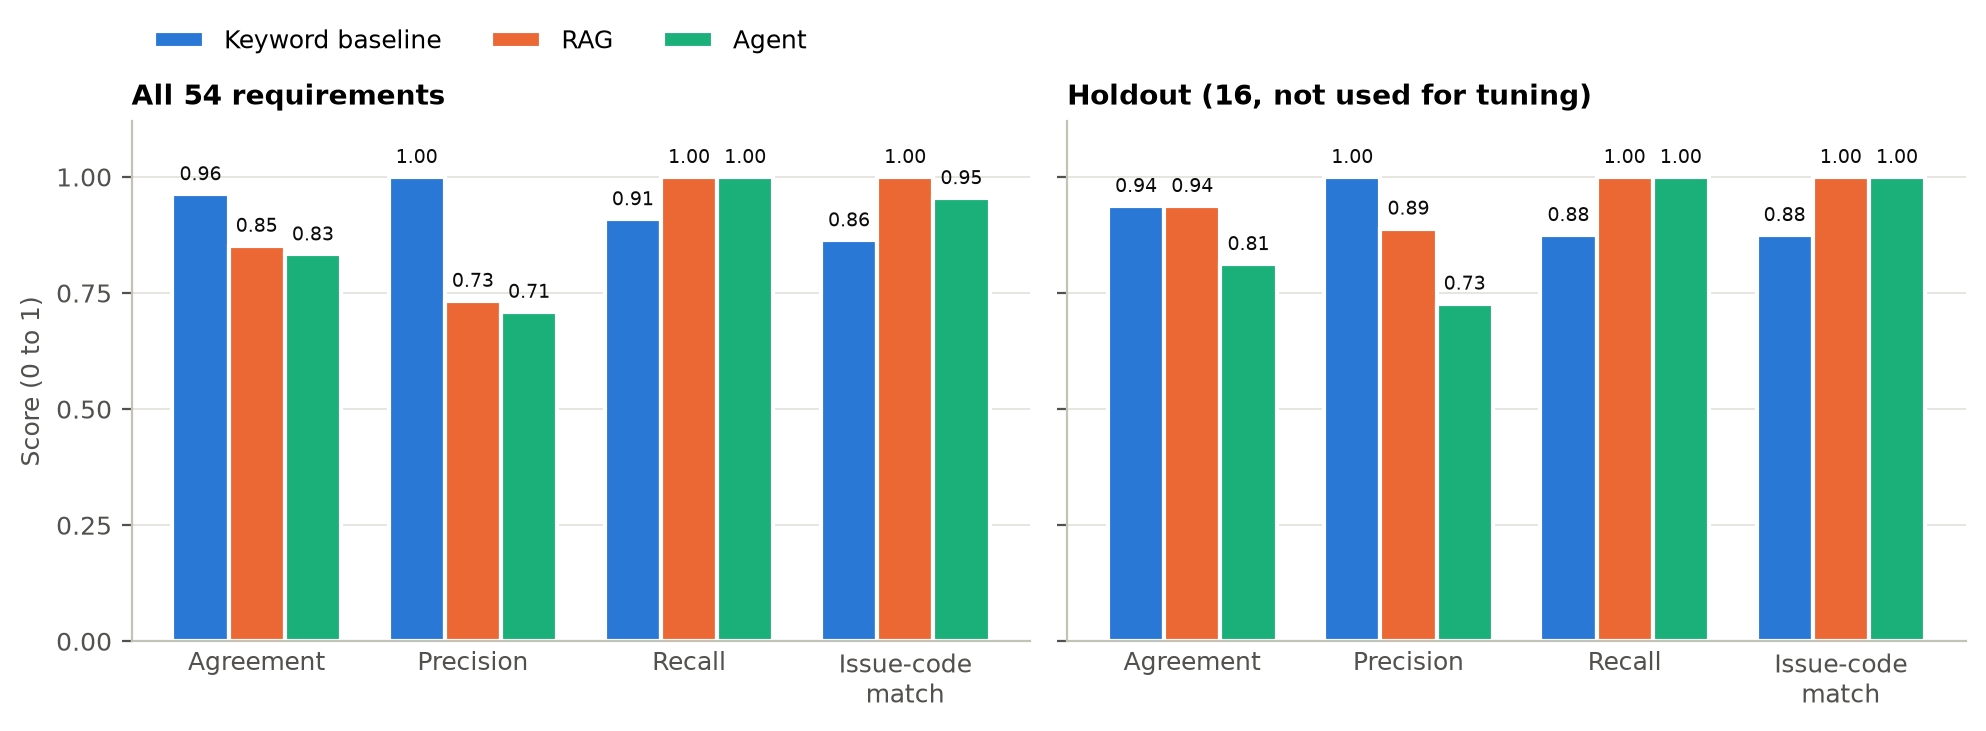

In [11]:
metrics = ["agreement", "precision", "recall", "issue_code_share"]
metric_names = ["Agreement", "Precision", "Recall", "Issue-code\nmatch"]   # precision/recall are on NEEDS_REVIEW

plot_df = results.copy()
hits_total = plot_df["issue_code_match"].str.split("/", expand=True).astype(int)
plot_df["issue_code_share"] = hits_total[0] / hits_total[1]   # "19/22" -> 0.86

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
x = np.arange(len(metrics))
width = 0.26
for ax, split, title in zip(axes, ["ALL", "HOLDOUT"], ["All 54 requirements", "Holdout (16, not used for tuning)"]):
    for i, name in enumerate(systems):
        row = plot_df[(plot_df["split"] == split) & (plot_df["system"] == name)].iloc[0]
        values = [row[m] for m in metrics]
        bars = ax.bar(x + (i - 1) * width, values, width, color=COLORS[name], label=LABELS[name],
                      edgecolor="white", linewidth=1.5)   # white edge = small gap between bars
        for bar, v in zip(bars, values):
            ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.2f}", ha="center", va="bottom",
                    fontsize=7, color=INK)
    ax.set_title(title, loc="left")
    ax.set_xticks(x, metric_names)
    ax.set_ylim(0, 1.12)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.yaxis.grid(True, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", length=0)
axes[0].set_ylabel("Score (0 to 1)")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.22), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

### 2. Error trade-off

Bars to the left are real problems a system missed; bars to the right are fine requirements it flagged anyway.
The baseline errs toward missing problems; RAG and the agent err toward over-flagging.

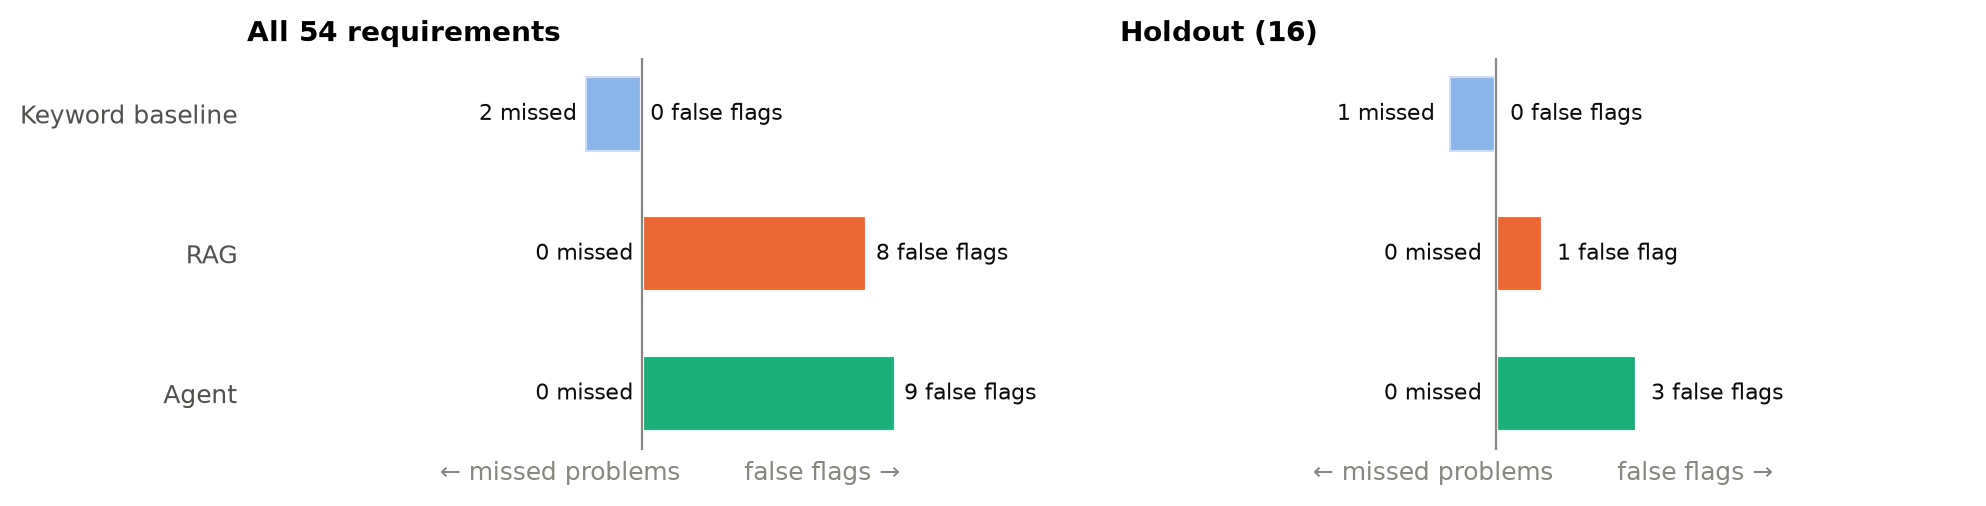

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True)
names = list(systems)
y = np.arange(len(names))[::-1]   # baseline on top
for ax, split, title in zip(axes, ["ALL", "HOLDOUT"], ["All 54 requirements", "Holdout (16)"]):
    sub = results[results["split"] == split].set_index("system")
    limit = max(sub["missed"].max(), sub["false_flags"].max()) + 2
    for yi, name in zip(y, names):
        missed, false_flags = sub.at[name, "missed"], sub.at[name, "false_flags"]
        ax.barh(yi, -missed, 0.55, color=COLORS[name], alpha=0.55, edgecolor="white", linewidth=1.5)
        ax.barh(yi, false_flags, 0.55, color=COLORS[name], edgecolor="white", linewidth=1.5)
        ax.text(-missed - 0.3, yi, f"{missed} missed", ha="right", va="center", fontsize=8, color=INK)
        ax.text(false_flags + 0.3, yi, f"{false_flags} false flag{'' if false_flags == 1 else 's'}", ha="left", va="center", fontsize=8, color=INK)
    ax.axvline(0, color=MUTED, linewidth=0.8)
    ax.set_xlim(-limit - 3, limit + 5)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title, loc="left")
    ax.set_xlabel("\u2190 missed problems        false flags \u2192", color=MUTED)
axes[0].set_yticks(y, [LABELS[n] for n in names])
fig.tight_layout()
plt.show()

### 3. Requirement by requirement

The 14 requirements at least one system gets wrong. Each cell is that system's result against the key. Every other
requirement is correct for all three systems.

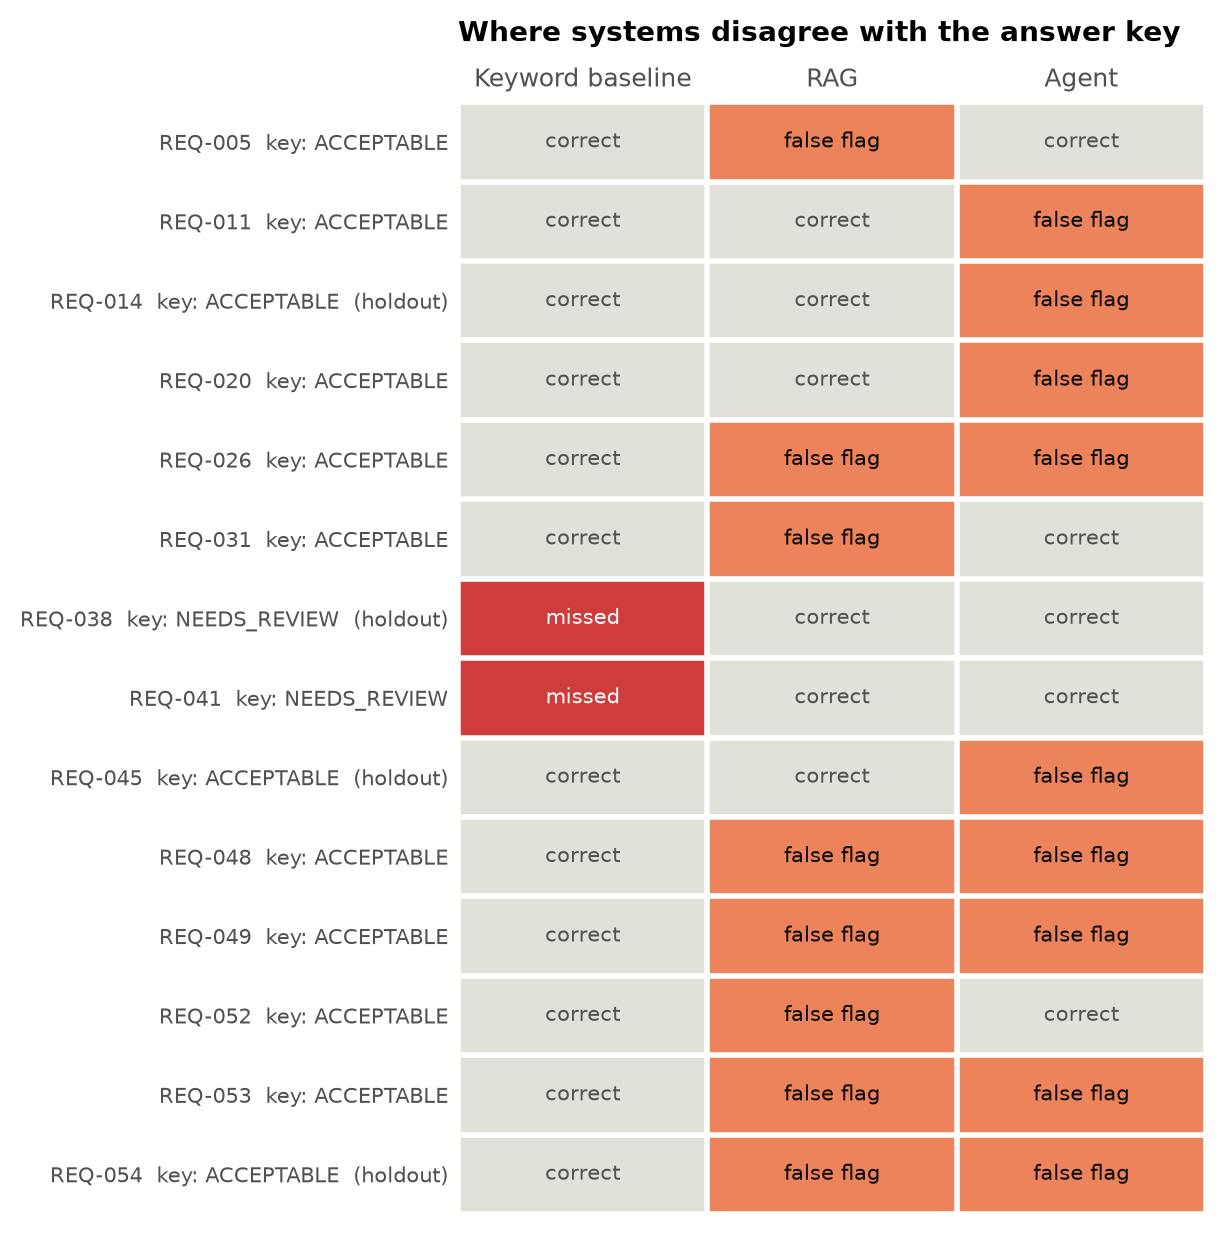

In [13]:
OUTCOMES = ["correct", "false flag", "missed"]
OUTCOME_COLORS = ["#e1e0d9", "#ec835a", "#d03b3b"]   # neutral, then two error colors
OUTCOME_TEXT = ["#52514e", "#0b0b0b", "#ffffff"]   # dark text on the light orange for contrast


def outcome(expected, predicted):
    if predicted == expected:
        return 0
    return 1 if predicted == "NEEDS_REVIEW" else 2


grid_rows = wrong_somewhere.reset_index(drop=True)
grid = np.array([[outcome(r["expected_outcome"], r[n]) for n in names] for _, r in grid_rows.iterrows()])

fig, ax = plt.subplots(figsize=(6.2, 0.36 * len(grid_rows) + 1.2))
ax.imshow(grid, cmap=plt.matplotlib.colors.ListedColormap(OUTCOME_COLORS), vmin=0, vmax=2, aspect="auto")
for (r, c), v in np.ndenumerate(grid):
    ax.text(c, r, OUTCOMES[v], ha="center", va="center", fontsize=7.5, color=OUTCOME_TEXT[v])

# White lines between cells
ax.set_xticks(np.arange(-0.5, len(names)), minor=True)
ax.set_yticks(np.arange(-0.5, len(grid_rows)), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0)
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_xticks(range(len(names)), [LABELS[n] for n in names])
ax.xaxis.tick_top()
row_labels = [f"{r.req_id.replace('SFMC-', '')}  key: {r.expected_outcome}{'  (holdout)' if r.split == 'HOLDOUT' else ''}"
              for r in grid_rows.itertuples()]
ax.set_yticks(range(len(grid_rows)), row_labels, fontsize=7.5)
ax.set_title("Where systems disagree with the answer key", loc="left", pad=22)
fig.tight_layout()
plt.show()

## Findings

Numbers are from the outputs merged on 2026-11-05.

- **Fair comparison (HOLDOUT, 16 requirements):** baseline 15/16, RAG 15/16, agent 13/16. RAG and the agent catch
  every requirement the key flags (recall 1.00); the baseline misses one (REQ-038).
- **All 54:** the baseline scores highest (52/54, precision 1.00, recall 0.91), but this is optimistic: its keyword
  rules were written alongside the same manual review that makes up most of these rows.
- **The baseline misses problems without a trigger word.** REQ-038 ("normal operation" isn't a defined mode) and
  REQ-041 (circular "recoverable fault") have no vague word for a regex to find. Both LLM systems catch them.
- **The LLM systems over-flag.** RAG has 8 false flags, the agent 9, almost all UNDEFINED_TERM or SCOPE_AMBIGUITY on
  security and interface requirements (REQ-048, 049, 053, 054) and on "pilot shall" / "personnel shall" wording
  (REQ-031, 053) that the key treats as style, not a defect. Some of these are judgment calls worth a second look
  in the key (e.g. REQ-026, "health" is never defined).
- **Issue codes:** RAG names the key's code on all 22 flagged requirements, the agent on 21, the baseline on 19
  (it has no SCOPE_AMBIGUITY rule).
- **Citations:** every citation from all three systems points to a real clause. This checks that citations exist,
  not that they are the most relevant clause; the key has no gold citations to check relevance against.
- **Not covered:** relationship, document and SWE-coverage cases (14 in the key) are not generated by any system yet.

In [14]:
# Sanity checks: every system reviewed every requirement in the key, once
for name, pred in systems.items():
    assert pred["req_id"].is_unique, f"{name} has duplicate requirements"
    assert set(pred["req_id"]) == set(req_key["req_id"]), f"{name} does not cover the same 54 requirements"
print("all three systems cover the same", len(req_key), "requirements")

all three systems cover the same 54 requirements
